<a href="https://colab.research.google.com/github/muslah26/Digital_Image_Processing/blob/main/Assignment%201/1.1_Color_Model_Conversion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/Assignment 1"

os.makedirs(BASE_DIR, exist_ok=True)

os.makedirs(f"{BASE_DIR}/output/1.1", exist_ok=True)
os.makedirs(f"{BASE_DIR}/output/1.2", exist_ok=True)
os.makedirs(f"{BASE_DIR}/output/1.3", exist_ok=True)

print("Assignment 1 folder created successfully!")

Assignment 1 folder created successfully!


In [ ]:
!pip install opencv-python-headless numpy matplotlib

In [ ]:
from google.colab import files
import shutil

uploaded = files.upload()

for filename in uploaded.keys():
    shutil.move(
        filename,
        f"{BASE_DIR}/input.jpg"
    )

print("Image uploaded successfully!")

Saving tp1wE4IOlDFAkQuVPPfH6_7Kkq0WkfpUtEINXJUl5M0DMEtx5xqjIqlZ_XflClrp-ItAMOPxcaGee4Wb9rTeqsTV07E9MSr_2nMGVwjlFlCxLLdyRfJhHfuqS41S4LET-YCSjf6WT0SOonXl9ZMyFmjDIsrMrYVvA337nGYcp2Is5JOQCLxEuWf8JkgQTp-x.jpeg to tp1wE4IOlDFAkQuVPPfH6_7Kkq0WkfpUtEINXJUl5M0DMEtx5xqjIqlZ_XflClrp-ItAMOPxcaGee4Wb9rTeqsTV07E9MSr_2nMGVwjlFlCxLLdyRfJhHfuqS41S4LET-YCSjf6WT0SOonXl9ZMyFmjDIsrMrYVvA337nGYcp2Is5JOQCLxEuWf8JkgQTp-x.jpeg
Image uploaded successfully!


In [ ]:
%%writefile "/content/drive/MyDrive/Assignment 1/1.1_Color_Model_Conversion.py"

import cv2
import matplotlib.pyplot as plt
import os

BASE_DIR = "/content/drive/MyDrive/Assignment 1"
image_path = f"{BASE_DIR}/input.jpg"
output_dir = f"{BASE_DIR}/output/1.1"

# Read original image
img = cv2.imread(image_path)

if img is None:
    raise FileNotFoundError("Input image not found!")

# Convert color models
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)

# Save converted images
cv2.imwrite(f"{output_dir}/grayscale.jpg", gray)
cv2.imwrite(f"{output_dir}/hsv.jpg", hsv)
cv2.imwrite(f"{output_dir}/lab.jpg", lab)

# Display results
images = [rgb, gray, hsv, lab]
titles = ["Original RGB", "Grayscale", "HSV", "LAB"]

plt.figure(figsize=(12, 8))

for i in range(4):
    plt.subplot(2, 2, i + 1)

    if i == 0:
        plt.imshow(images[i])
    elif i == 1:
        plt.imshow(images[i], cmap="gray")
    elif i == 2:
        plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_HSV2RGB))
    else:
        plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_LAB2RGB))

    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.savefig(f"{output_dir}/color_conversion_results.png")
plt.show()

print("Task 1.1 completed successfully!")

Writing /content/drive/MyDrive/Assignment 1/1.1_Color_Model_Conversion.py


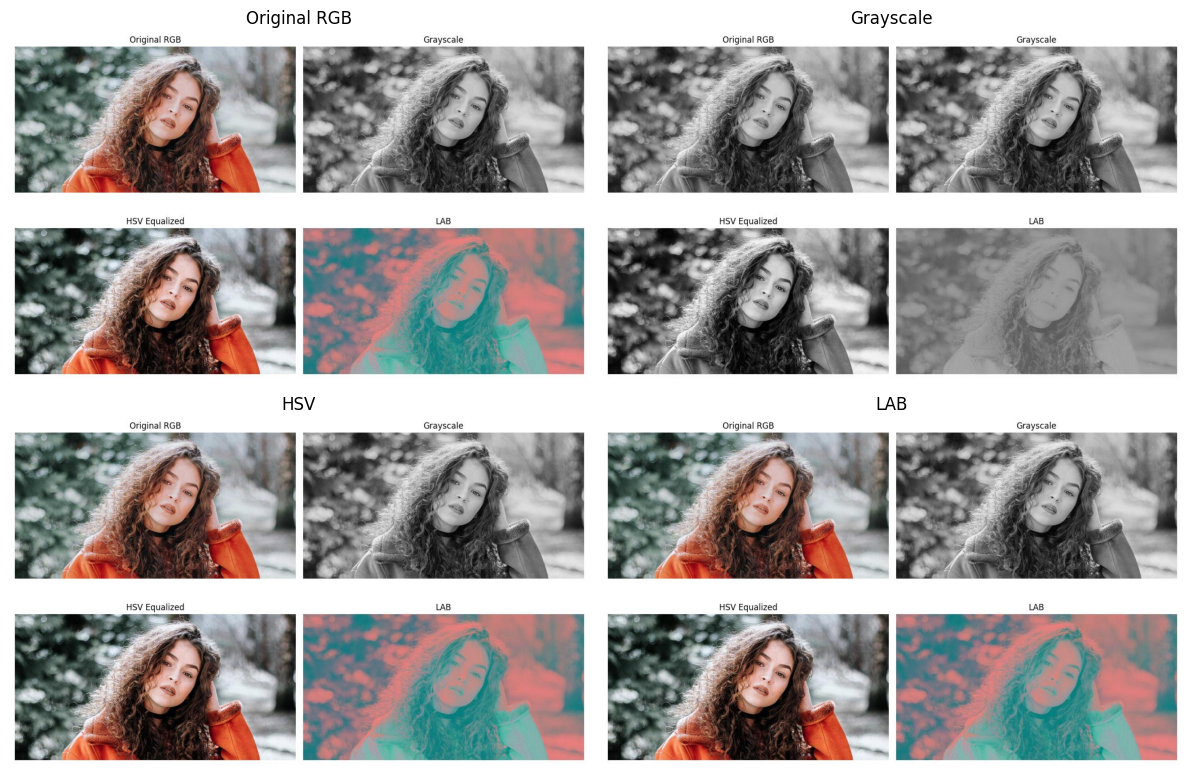

Task 1.1 completed successfully!


<Figure size 640x480 with 0 Axes>

In [ ]:
%run "/content/drive/MyDrive/Assignment 1/1.1_Color_Model_Conversion.py"

In [ ]:
%%writefile "/content/drive/MyDrive/Assignment 1/1.2_Affine_Transformation.py"

import cv2
import numpy as np
import matplotlib.pyplot as plt

BASE_DIR = "/content/drive/MyDrive/Assignment 1"
image_path = f"{BASE_DIR}/input.jpg"
output_dir = f"{BASE_DIR}/output/1.2"

# Read image
img = cv2.imread(image_path)

if img is None:
    raise FileNotFoundError("Input image not found!")

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

height, width = img.shape[:2]

# 1. Translation
translation_matrix = np.float32([
    [1, 0, 100],
    [0, 1, 50]
])

translated = cv2.warpAffine(
    img, translation_matrix, (width, height)
)

# 2. Rotation
rotation_matrix = cv2.getRotationMatrix2D(
    (width // 2, height // 2), 45, 1
)

rotated = cv2.warpAffine(
    img, rotation_matrix, (width, height)
)

# 3. Scaling
scaled = cv2.resize(
    img, None, fx=1.5, fy=1.5,
    interpolation=cv2.INTER_LINEAR
)

# Save results
cv2.imwrite(
    f"{output_dir}/translated.jpg",
    cv2.cvtColor(translated, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    f"{output_dir}/rotated.jpg",
    cv2.cvtColor(rotated, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    f"{output_dir}/scaled.jpg",
    cv2.cvtColor(scaled, cv2.COLOR_RGB2BGR)
)

# Display results
images = [img, translated, rotated, scaled]
titles = ["Original", "Translation", "Rotation 45 Degrees", "Scaling 1.5x"]

plt.figure(figsize=(12, 8))

for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i])
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.savefig(f"{output_dir}/affine_results.png")
plt.show()

print("Task 1.2 completed successfully!")

Writing /content/drive/MyDrive/Assignment 1/1.2_Affine_Transformation.py


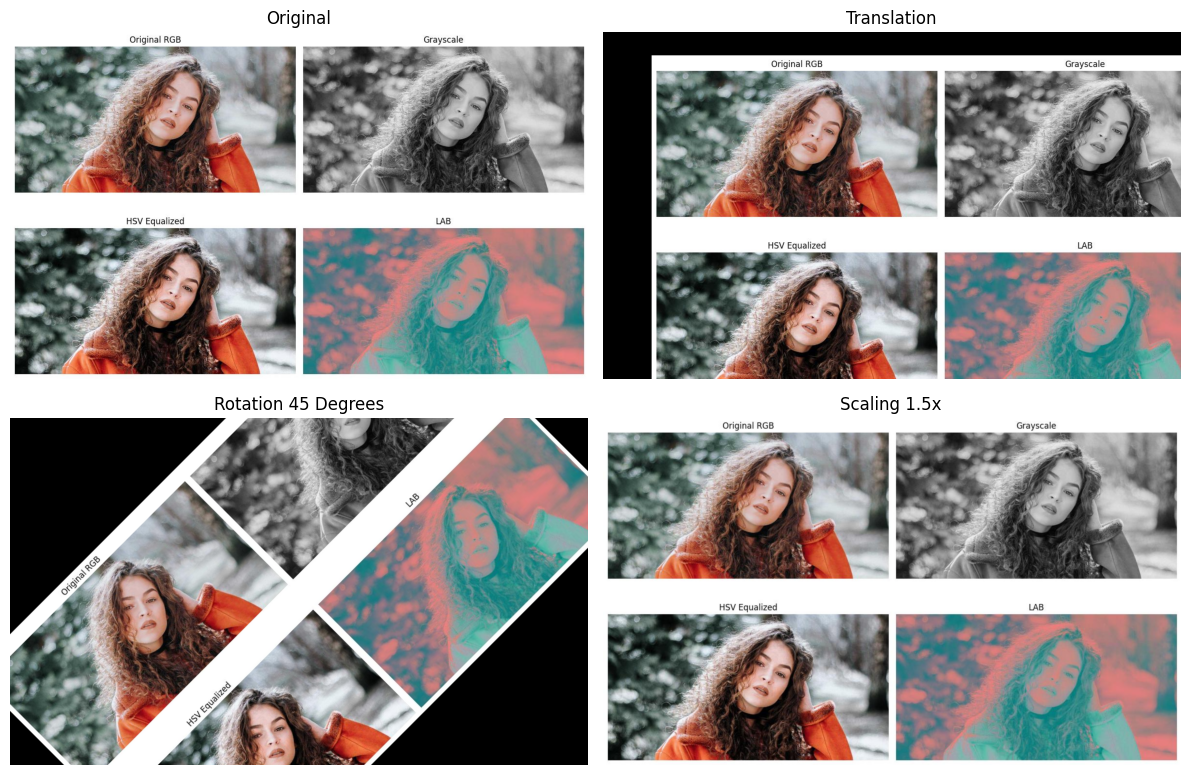

Task 1.2 completed successfully!


<Figure size 640x480 with 0 Axes>

In [ ]:
%run "/content/drive/MyDrive/Assignment 1/1.2_Affine_Transformation.py"

In [ ]:
%%writefile "/content/drive/MyDrive/Assignment 1/1.3_Spatial_Interpolation.py"

import cv2
import matplotlib.pyplot as plt

BASE_DIR = "/content/drive/MyDrive/Assignment 1"
image_path = f"{BASE_DIR}/input.jpg"
output_dir = f"{BASE_DIR}/output/1.3"

# Read original image
img = cv2.imread(image_path)

if img is None:
    raise FileNotFoundError("Input image not found!")

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Resize dimensions
height, width = img.shape[:2]

new_width = width * 2
new_height = height * 2

# 1. Nearest Neighbor
nearest = cv2.resize(
    img,
    (new_width, new_height),
    interpolation=cv2.INTER_NEAREST
)

# 2. Bilinear
bilinear = cv2.resize(
    img,
    (new_width, new_height),
    interpolation=cv2.INTER_LINEAR
)

# 3. Bicubic
bicubic = cv2.resize(
    img,
    (new_width, new_height),
    interpolation=cv2.INTER_CUBIC
)

# Save images
cv2.imwrite(
    f"{output_dir}/nearest_neighbor.jpg",
    cv2.cvtColor(nearest, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    f"{output_dir}/bilinear.jpg",
    cv2.cvtColor(bilinear, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    f"{output_dir}/bicubic.jpg",
    cv2.cvtColor(bicubic, cv2.COLOR_RGB2BGR)
)

# Display results
images = [img, nearest, bilinear, bicubic]

titles = [
    "Original Image",
    "Nearest Neighbor",
    "Bilinear Interpolation",
    "Bicubic Interpolation"
]

plt.figure(figsize=(12, 8))

for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i])
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.savefig(f"{output_dir}/interpolation_results.png")
plt.show()

print("Task 1.3 completed successfully!")

Writing /content/drive/MyDrive/Assignment 1/1.3_Spatial_Interpolation.py


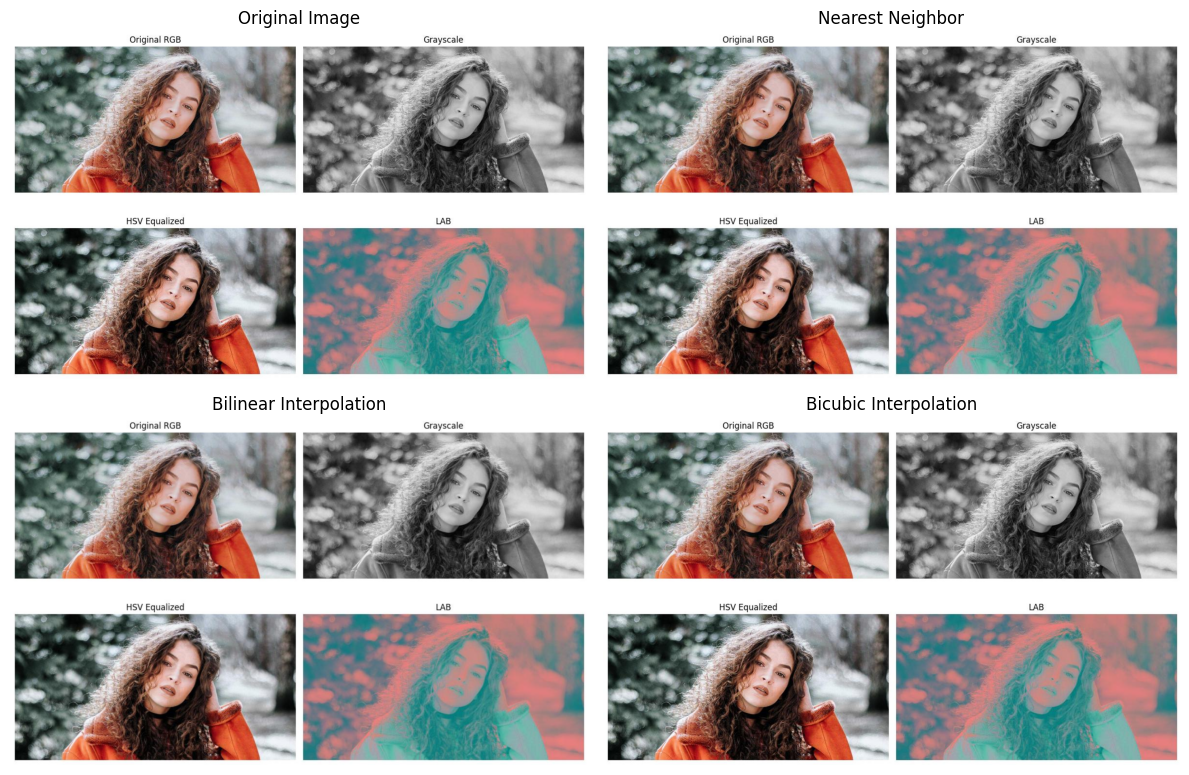

Task 1.3 completed successfully!


<Figure size 640x480 with 0 Axes>

In [ ]:
%run "/content/drive/MyDrive/Assignment 1/1.3_Spatial_Interpolation.py"

========== ASSIGNMENT 1 ==========

Running Task 1.1...


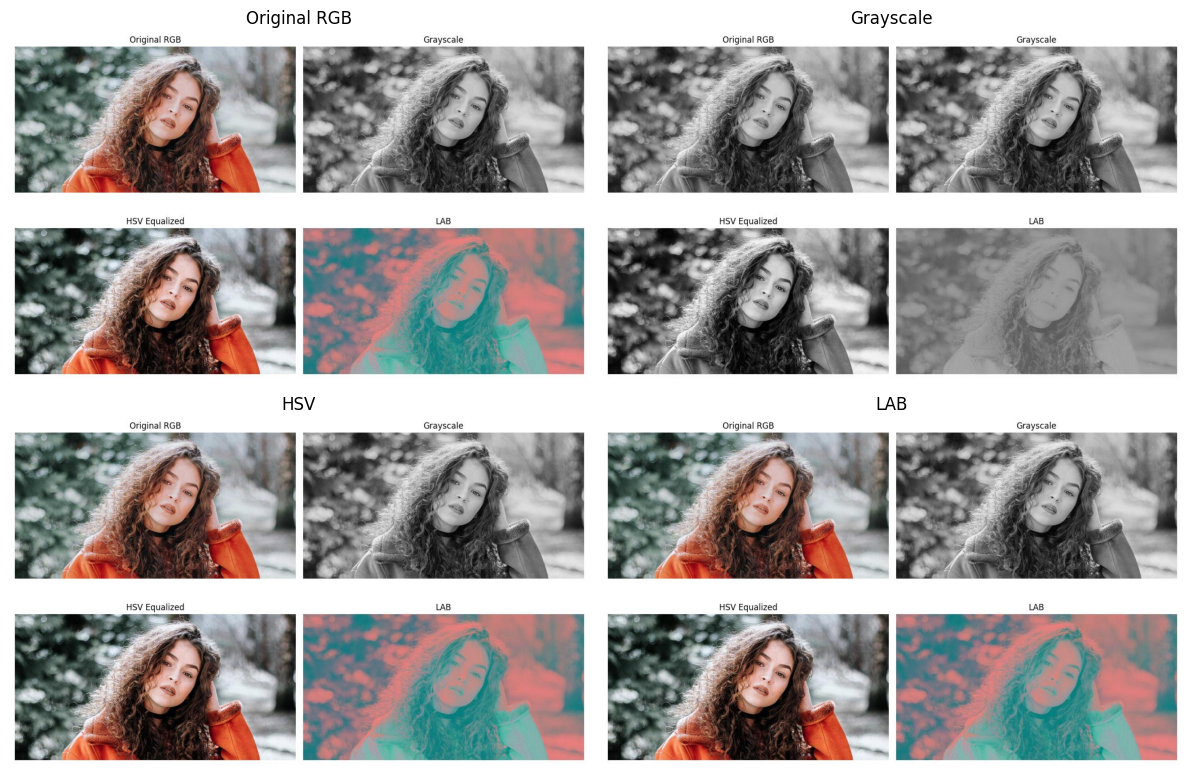

Task 1.1 completed successfully!

Running Task 1.2...


<Figure size 640x480 with 0 Axes>

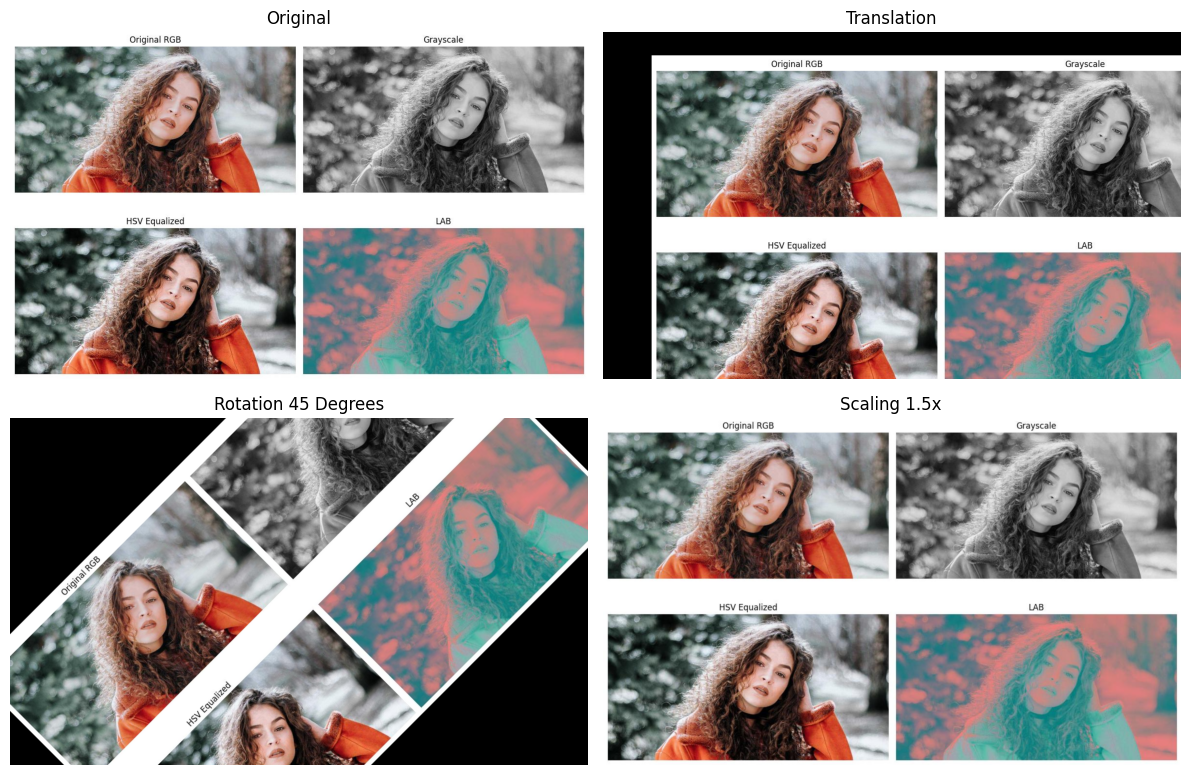

Task 1.2 completed successfully!

Running Task 1.3...


<Figure size 640x480 with 0 Axes>

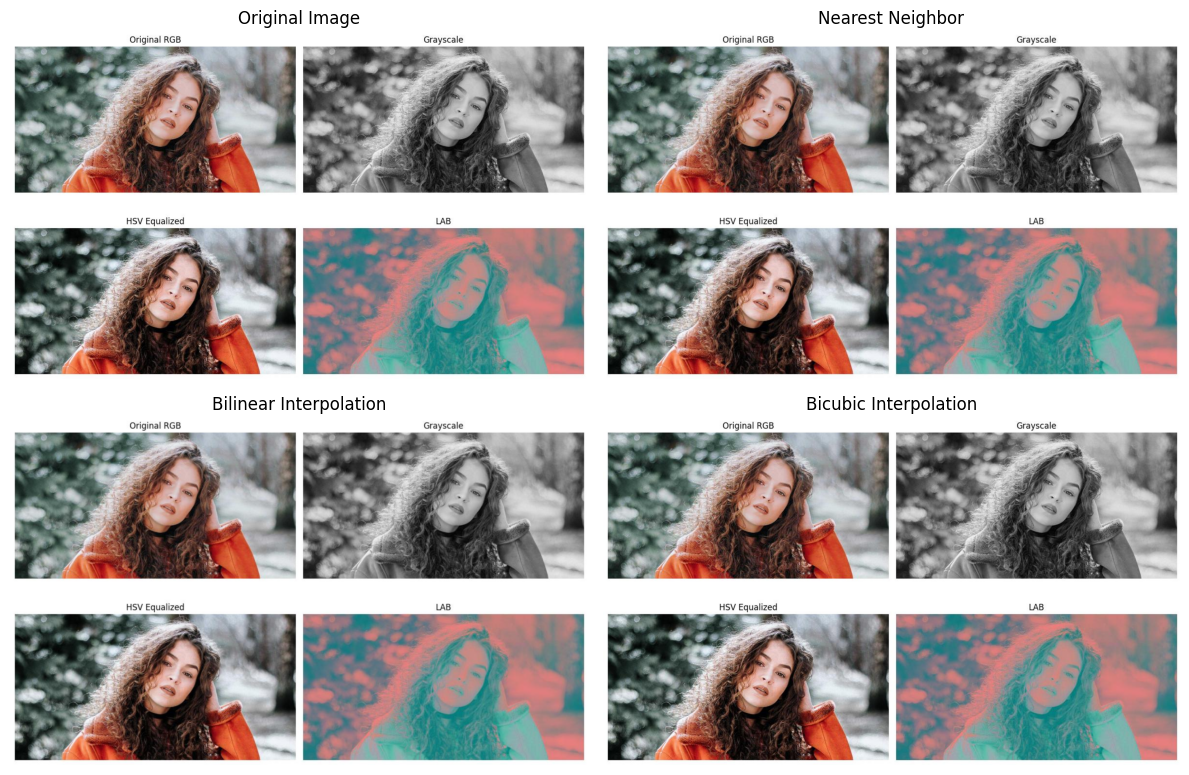

Task 1.3 completed successfully!

========== ALL TASKS COMPLETED ==========


<Figure size 640x480 with 0 Axes>

In [ ]:
print("========== ASSIGNMENT 1 ==========")

print("\nRunning Task 1.1...")
%run "/content/drive/MyDrive/Assignment 1/1.1_Color_Model_Conversion.py"

print("\nRunning Task 1.2...")
%run "/content/drive/MyDrive/Assignment 1/1.2_Affine_Transformation.py"

print("\nRunning Task 1.3...")
%run "/content/drive/MyDrive/Assignment 1/1.3_Spatial_Interpolation.py"

print("\n========== ALL TASKS COMPLETED ==========")

In [ ]:
for root, dirs, files_list in os.walk(BASE_DIR):
    print(root)

    for file in files_list:
        print("   └──", file)

/content/drive/MyDrive/Assignment 1
   └── input.jpg
   └── 1.1_Color_Model_Conversion.py
   └── 1.2_Affine_Transformation.py
   └── 1.3_Spatial_Interpolation.py
/content/drive/MyDrive/Assignment 1/output
/content/drive/MyDrive/Assignment 1/output/1.1
   └── grayscale.jpg
   └── hsv.jpg
   └── lab.jpg
   └── color_conversion_results.png
/content/drive/MyDrive/Assignment 1/output/1.2
   └── translated.jpg
   └── rotated.jpg
   └── scaled.jpg
   └── affine_results.png
/content/drive/MyDrive/Assignment 1/output/1.3
   └── nearest_neighbor.jpg
   └── bilinear.jpg
   └── bicubic.jpg
   └── interpolation_results.png


In [ ]:
!git --version

git version 2.43.0


In [ ]:
!git config --global user.name "muslah26"
!git config --global user.email "232031057@feniuniversity.ac.bd"

In [ ]:
import getpass
import subprocess

github_username = input("muslah26")
github_token = getpass.getpass("https://github.com/settings/personal-access-tokens/22561643")

# Temporarily cache GitHub credentials in this Colab runtime
subprocess.run(
    ["git", "config", "--global", "credential.helper",
     "cache --timeout=3600"],
    check=True
)

credential = (
    f"protocol=https\n"
    f"host=github.com\n"
    f"username={muslah26}\n"
    f"password={https://github.com/settings/personal-access-tokens/22561643}\n\n"
)

subprocess.run(
    ["git", "credential", "approve"],
    input=credential,
    text=True,
    check=True
)

github_token = None

print("GitHub authentication configured!")

KeyboardInterrupt: Interrupted by user

In [ ]:
import getpass
import subprocess

github_username = input("Enter your GitHub username:@muslah26 ")
github_token = getpass.getpass("Paste your GitHub token:https://github.com/settings/personal-access-tokens/22561643 ")

# Temporarily cache GitHub credentials in this Colab runtime
subprocess.run(
    ["git", "config", "--global", "credential.helper",
     "cache --timeout=3600"],
    check=True
)

credential = (
    f"protocol=https\n"
    f"host=github.com\n"
    f"username={@muslah26}\n"
    f"password={import getpass
import subprocess

github_username = input("Enter your GitHub username: @muslah26")
github_token = getpass.getpass("Paste your GitHub token: https://github.com/settings/personal-access-tokens/22561643")

# Temporarily cache GitHub credentials in this Colab runtime
subprocess.run(
    ["git", "config", "--global", "credential.helper",
     "cache --timeout=3600"],
    check=True
)

credential = (
    f"protocol=https\n"
    f"host=github.com\n"
    f"username={muslah26}\n"
    f"password={https://github.com/settings/personal-access-tokens/22561643}\n\n"
)

subprocess.run(
    ["git", "credential", "approve"],
    input=credential,
    text=True,
    check=True
)

github_token = None

print("GitHub authentication configured!")}\n\n"
)

subprocess.run(
    ["git", "credential", "approve"],
    input=credential,
    text=True,
    check=True
)

github_token = None

print("GitHub authentication configured!")

SyntaxError: f-string: expecting a valid expression after '{' (465940950.py, line 17)

In [ ]:
import os

REPO_URL = "https://github.com/muslah26/Digital_Image_Processing"

REPO_DIR = "/content/Digital-Image-Processing"

!git clone {REPO_URL} {REPO_DIR}

Cloning into '/content/Digital-Image-Processing'...


In [ ]:
!ls -la /content/Digital-Image-Processing

total 12
drwxr-xr-x 3 root root 4096 Nov  7 18:24 .
drwxr-xr-x 1 root root 4096 Nov  7 18:24 ..
drwxr-xr-x 7 root root 4096 Nov  7 18:24 .git


In [ ]:
import shutil
import os

SOURCE_DIR = "/content/drive/MyDrive/Assignment 1"
DEST_DIR = "/content/Digital-Image-Processing/Assignment 1"

shutil.copytree(
    SOURCE_DIR,
    DEST_DIR,
    dirs_exist_ok=True
)

print("Assignment 1 copied successfully!")

Assignment 1 copied successfully!


In [ ]:
%cd /content/Digital-Image-Processing

!git add .

/content/Digital-Image-Processing


In [ ]:
!git commit -m "Add Assignment 1 - Digital Image Processing"

[main (root-commit) 076820d] Add Assignment 1 - Digital Image Processing
 16 files changed, 211 insertions(+)
 create mode 100644 Assignment 1/1.1_Color_Model_Conversion.py
 create mode 100644 Assignment 1/1.2_Affine_Transformation.py
 create mode 100644 Assignment 1/1.3_Spatial_Interpolation.py
 create mode 100644 Assignment 1/input.jpg
 create mode 100644 Assignment 1/output/1.1/color_conversion_results.png
 create mode 100644 Assignment 1/output/1.1/grayscale.jpg
 create mode 100644 Assignment 1/output/1.1/hsv.jpg
 create mode 100644 Assignment 1/output/1.1/lab.jpg
 create mode 100644 Assignment 1/output/1.2/affine_results.png
 create mode 100644 Assignment 1/output/1.2/rotated.jpg
 create mode 100644 Assignment 1/output/1.2/scaled.jpg
 create mode 100644 Assignment 1/output/1.2/translated.jpg
 create mode 100644 Assignment 1/output/1.3/bicubic.jpg
 create mode 100644 Assignment 1/output/1.3/bilinear.jpg
 create mode 100644 Assignment 1/output/1.3/interpolation_results.png
 create m

In [ ]:
!git branch -M main
!git push -u origin main

fatal: could not read Username for 'https://github.com': No such device or address


In [ ]:
import getpass
import subprocess

username = input("GitHub username: ")
token = getpass.getpass("GitHub Personal Access Token: ")

credential = (
    f"protocol=https\n"
    f"host=github.com\n"
    f"username={muslah26}\n"
    f"password={232031057}\n\n"
)

subprocess.run(
    ["git", "credential", "approve"],
    input=credential,
    text=True,
    check=True
)

print("Authentication configured!")

KeyboardInterrupt: Interrupted by user

In [ ]:
%cd /content/Digital-Image-Processing

!git remote set-url origin https://github.com/muslah26/Digital_Image_Processing.git

!git remote -v

/content/Digital-Image-Processing
origin	https://github.com/muslah26/Digital_Image_Processing.git (fetch)
origin	https://github.com/muslah26/Digital_Image_Processing.git (push)


In [ ]:
import getpass
import subprocess

token = getpass.getpass("Enter GitHub Personal Access Token: ")

credential = (
    "protocol=https\n"
    "host=github.com\n"
    "username=muslah26\n"
    f"password={token}\n\n"
)

subprocess.run(
    ["git", "credential", "approve"],
    input=credential,
    text=True,
    check=True
)

del token

print("Authentication configured!")

KeyboardInterrupt: Interrupted by user